## **<center>Penerapan Prompt yang baik dalam Permasalahan Eksplorasi Mineral</center>**

##### **<center>Abednego R. Pasorong_H061241063</center>**
___

**Penerapan Prompt Membahas:**

- Prompt 1
Mineralisasi logam (Resistivitas dan IP)

- Prompt 2
Struktur dan mineral bermagnet (Magnetik)

- Prompt 3
Mineral konduktif (Elektromagnetik)

- Prompt 4
Struktur dan alterasi hidrotermal (Magnetotellurik)

- Prompt 5
Penentuan target eksplorasi (Integrasi Metode Geofisika)

___

##### **Prompt 1: Identifikasi Zona Mineralisasi Logam Menggunakan Metode Resistivitas dan IP**

- **R — Role (Peran)**

    Kamu adalah seorang ahli geofisika eksplorasi yang memiliki pengalaman dalam metode geolistrik resistivitas dan Induced Polarization (IP) untuk eksplorasi mineral logam.

- **T — Task (Tugas)**

    Analisis dan interpretasikan data resistivitas dan chargeability untuk mengidentifikasi zona yang berpotensi mengandung mineralisasi logam di bawah permukaan.

- **C — Context (Konteks)**

    Survei dilakukan pada daerah yang diduga memiliki potensi mineralisasi sulfida. Metode resistivitas digunakan untuk mengetahui variasi sifat kelistrikan batuan, sedangkan IP digunakan untuk mendeteksi material yang memiliki kemampuan polarisasi, seperti mineral sulfida terdiseminasi.

- **I — Input (Masukan)**

    Data yang tersedia berupa penampang resistivitas dengan rentang 50–1.500 Ωm dan chargeability 2–50 mV/V, dengan kedalaman investigasi sekitar 100 meter.

- **K — Constraints (Batasan)**

    1. Gunakan konsep dasar resistivitas dan IP dalam interpretasi.
    
    2. Jangan menentukan jenis mineral hanya berdasarkan nilai resistivitas atau chargeability.
    
    3. Bedakan antara anomali geofisika dan bukti keberadaan mineral secara langsung.
    
    4. Jika data tidak mencukupi, nyatakan keterbatasan interpretasi.

- **O — Output (Hasil)**

    Sajikan hasil dalam bentuk:
    1. Tabel zona anomali, nilai resistivitas, chargeability, dan interpretasi geologi.
    
    2. Penjelasan singkat mengenai zona yang berpotensi mengalami mineralisasi.
    
    3. Kesimpulan mengenai potensi mineralisasi dan rekomendasi survei lanjutan.

- **Q — Quality Criteria (Kriteria Kualitas)**

    Jawaban harus menggunakan istilah geofisika yang tepat, memiliki alasan ilmiah pada setiap interpretasi, serta menjelaskan hubungan antara resistivitas, chargeability, dan kondisi geologi.

- **V — Verification (Verifikasi)**

    Periksa konsistensi satuan dan rentang nilai data. Pastikan interpretasi resistivitas dan chargeability tidak saling bertentangan tanpa penjelasan. Jangan menyatakan keberadaan bijih secara pasti tanpa dukungan data geologi atau pengeboran.
___





##### **Implementasi Phyton dan Output**

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Mengatur angka acak agar hasil simulasi konsisten
np.random.seed(42)

print("Library berhasil diimpor.")

Library berhasil diimpor.


In [20]:
# Membuat koordinat lintasan dan kedalaman
x = np.arange(0, 201, 5)
z = np.arange(0, 51, 2)

# Membuat grid dua dimensi
X, Z = np.meshgrid(x, z)

# Model awal resistivitas (Ohm.m)
rho = (
    180
    + 35 * np.sin(X / 28)
    + 15 * np.cos(Z / 7)
)

# Model awal chargeability (mV/V)
chargeability = (
    10
    + 2.5 * np.sin(X / 22)
    + 1.5 * np.cos(Z / 5)
)

print("Model bawah permukaan berhasil dibuat.")
print("Ukuran grid:", rho.shape)

Model bawah permukaan berhasil dibuat.
Ukuran grid: (26, 41)


In [21]:
# Menentukan lokasi zona anomali
zona = (
    (X >= 80) & (X <= 120) &
    (Z >= 10) & (Z <= 26)
)

# Mengisi zona anomali dengan resistivitas rendah
rho[zona] = (
    27 + np.random.normal(0, 3, np.count_nonzero(zona))
)

# Mengisi zona anomali dengan chargeability tinggi
chargeability[zona] = (
    32 + np.random.normal(0, 2.5, np.count_nonzero(zona))
)

# Menambahkan variasi acak kecil agar model tidak terlalu seragam
rho += np.random.normal(0, 5, rho.shape)
chargeability += np.random.normal(0, 1.5, chargeability.shape)

# Memastikan nilai tetap positif
rho = np.clip(rho, 10, None)
chargeability = np.clip(chargeability, 0, None)

print("Zona anomali berhasil dibuat.")

Zona anomali berhasil dibuat.


In [22]:
# Menentukan kriteria anomali
anomali = (rho < 50) & (chargeability > 20)

# Memeriksa apakah anomali ditemukan
if np.any(anomali):

    # Menghitung batas zona anomali
    x_min = X[anomali].min()
    x_max = X[anomali].max()
    z_min = Z[anomali].min()
    z_max = Z[anomali].max()

    # Menghitung nilai rata-rata dalam zona anomali
    rho_mean = rho[anomali].mean()
    m_mean = chargeability[anomali].mean()

    # Membuat tabel ringkasan
    hasil = pd.DataFrame({
        "Parameter": [
            "Jarak minimum (m)",
            "Jarak maksimum (m)",
            "Kedalaman minimum (m)",
            "Kedalaman maksimum (m)",
            "Resistivitas rata-rata (Ohm.m)",
            "Chargeability rata-rata (mV/V)",
            "Jumlah sel anomali"
        ],
        "Hasil": [
            x_min,
            x_max,
            z_min,
            z_max,
            round(rho_mean, 2),
            round(m_mean, 2),
            int(anomali.sum())
        ]
    })

    print("HASIL ANALISIS ZONA ANOMALI")
    display(hasil)

else:
    print("Tidak ditemukan zona yang memenuhi kriteria anomali.")

HASIL ANALISIS ZONA ANOMALI


,Parameter,Hasil
0,Jarak minimum (m),80.00
1,Jarak maksimum (m),120.00
2,Kedalaman minimum (m),10.00
3,Kedalaman maksimum (m),26.00
4,Resistivitas rata-rata (Ohm.m),26.05
5,Chargeability rata-rata (mV/V),32.09
6,Jumlah sel anomali,81.00


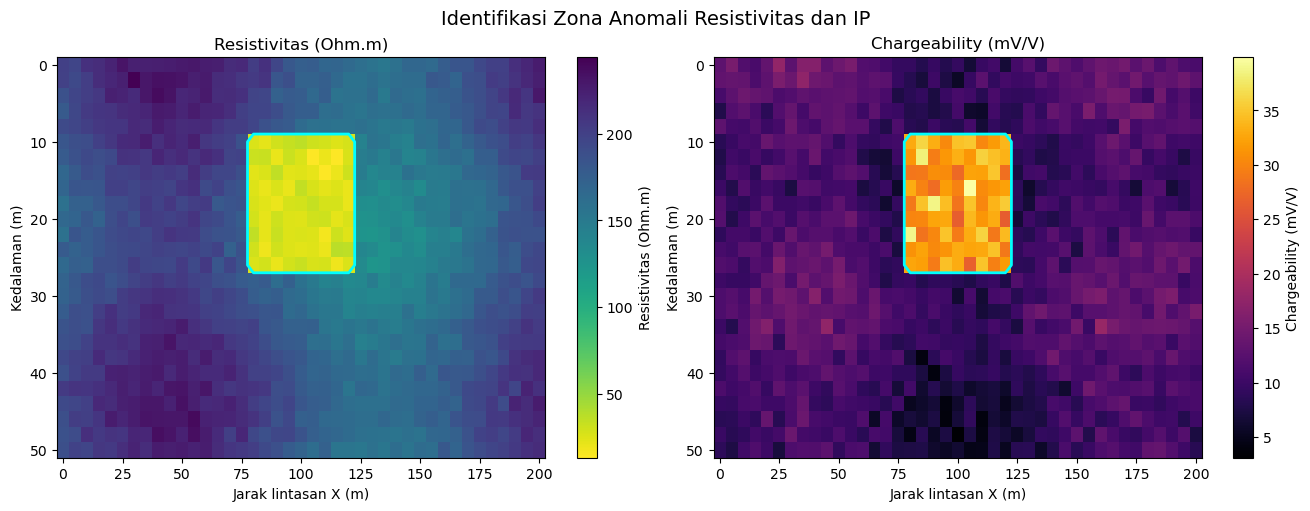

In [23]:
# Membuat dua grafik berdampingan
fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5),
    constrained_layout=True
)

# --------------------------------------------------
# Grafik 1: Resistivitas
# --------------------------------------------------
p1 = axes[0].pcolormesh(
    X, Z, rho,
    cmap="viridis_r",
    shading="auto"
)

axes[0].set_title("Resistivitas (Ohm.m)")
axes[0].set_xlabel("Jarak lintasan X (m)")
axes[0].set_ylabel("Kedalaman (m)")
axes[0].invert_yaxis()

fig.colorbar(
    p1,
    ax=axes[0],
    label="Resistivitas (Ohm.m)"
)

# --------------------------------------------------
# Grafik 2: Chargeability
# --------------------------------------------------
p2 = axes[1].pcolormesh(
    X, Z, chargeability,
    cmap="inferno",
    shading="auto"
)

axes[1].set_title("Chargeability (mV/V)")
axes[1].set_xlabel("Jarak lintasan X (m)")
axes[1].set_ylabel("Kedalaman (m)")
axes[1].invert_yaxis()

fig.colorbar(
    p2,
    ax=axes[1],
    label="Chargeability (mV/V)"
)

# Menampilkan batas zona anomali pada kedua grafik
if np.any(anomali):
    for ax in axes:
        ax.contour(
            X, Z, anomali.astype(float),
            levels=[0.5],
            colors="cyan",
            linewidths=2
        )

# Judul utama
fig.suptitle(
    "Identifikasi Zona Anomali Resistivitas dan IP",
    fontsize=14
)

# Menampilkan grafik
plt.show()

##### **Kesimpulan Interpretasi**

- Zona anomali terdeteksi pada jarak 80-120 meter.

- Kedalaman anomali sekitar 10-26 meter.

- Resistivitas rata-rata: 26.05 Ohm.m.

- Chargeability rata-rata: 32.09 mV/V.

- Interpretasi awal: kombinasi resistivitas rendah dan chargeability tinggi dapat menjadi indikasi zona yang perlu diteliti untuk kemungkinan mineralisasi sulfida.

- Rekomendasi: lakukan korelasi dengan pemetaan geologi, data geokimia, dan survei pendukung sebelum menetapkan target pengeboran.

- Catatan: hasil berasal dari data sintetis. Anomali geofisika tidak membuktikan keberadaan bijih secara pasti.
---

##### **Prompt 2: Pemetaan Zona Mineralisasi Menggunakan Metode Magnetik**

- **R — Role (Peran)**

    Kamu adalah seorang ahli geofisika eksplorasi yang berpengalaman dalam metode magnetik untuk pemetaan struktur geologi dan eksplorasi mineral logam.

- **T — Task (Tugas)**

    Analisis data anomali magnetik untuk mengidentifikasi struktur geologi, intrusi batuan, dan zona yang berpotensi berhubungan dengan mineralisasi logam.

- **C — Context (Konteks)**

    Survei magnetik dilakukan pada daerah yang diduga memiliki potensi mineralisasi besi atau mineral logam yang berasosiasi dengan batuan bermagnet tinggi. Variasi medan magnet bumi dapat digunakan untuk mengetahui perbedaan sifat kemagnetan batuan bawah permukaan.

- **I — Input (Masukan)**

    Data yang tersedia berupa peta anomali magnetik dengan nilai anomali total antara -500 hingga 1.000 nT, koordinat titik pengukuran, dan informasi geologi regional berupa persebaran batuan beku dan batuan sedimen.

- **K — Constraints (Batasan)**

    1. Gunakan konsep suseptibilitas magnetik dan variasi medan magnet.

    2. Pertimbangkan pengaruh kedalaman, bentuk, ukuran, dan arah magnetisasi sumber anomali.

    3. Jangan menganggap setiap anomali magnetik tinggi sebagai zona mineralisasi.

    4. Bedakan interpretasi struktur geologi dari interpretasi potensi mineral.

- **O — Output (Hasil)**
    Buatlah:

    1. Interpretasi zona anomali magnetik tinggi dan rendah.

    2. Tabel dugaan sumber anomali dan kemungkinan kondisi geologinya.

    3. Penjelasan mengenai zona target eksplorasi mineral.

    4. Kesimpulan dan rekomendasi metode geofisika pendukung.

- **Q — Quality Criteria (Kriteria Kualitas)**

    Interpretasi harus didasarkan pada konsep magnetik yang benar, mempertimbangkan kondisi geologi, dan menjelaskan alasan penentuan zona target secara sistematis.

- **V — Verification (Verifikasi)**

    Periksa satuan anomali dalam nT dan konsistensi data koordinat. Pastikan interpretasi memperhatikan kemungkinan pengaruh batuan nonmineralisasi yang memiliki suseptibilitas magnetik tinggi. Nyatakan ketidakpastian apabila informasi magnetisasi atau geologi belum tersedia.


##### **Implementasi Phyton dan Output**

PEMETAAN ZONA MINERALISASI MENGGUNAKAN METODE MAGNETIK

Grid survei berhasil dibuat.
Panjang lintasan X : 0 - 500 meter
Lebar area Y       : 0 - 300 meter

Model anomali magnetik berhasil dibuat.
Anomali minimum : -414.48 nT
Anomali maksimum: 859.47 nT

HASIL DETEKSI ANOMALI
---------------------------------------------
Ambang anomali kuat : ±250 nT
Jumlah sel anomali positif: 69
Jumlah sel anomali negatif: 55

TABEL HASIL ANALISIS ZONA


,Zona,X rata-rata (m),Y rata-rata (m),Anomali rata-rata (nT),Anomali minimum (nT),Anomali maksimum (nT),Jumlah sel
0,Anomali positif,151.2,128.1,474.32,251.26,859.47,69
1,Anomali negatif,363.8,189.6,-324.70,-414.48,-251.31,55


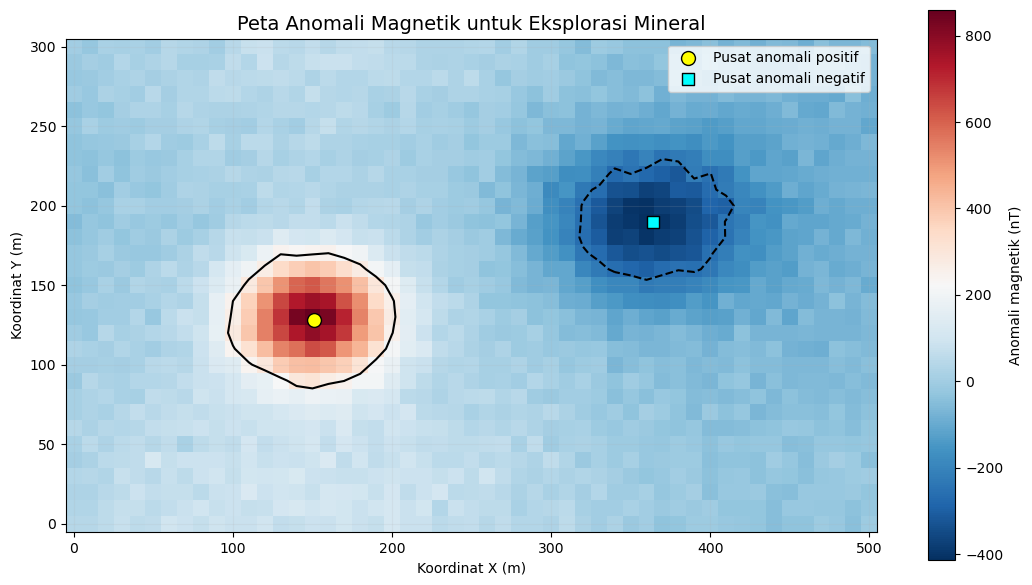

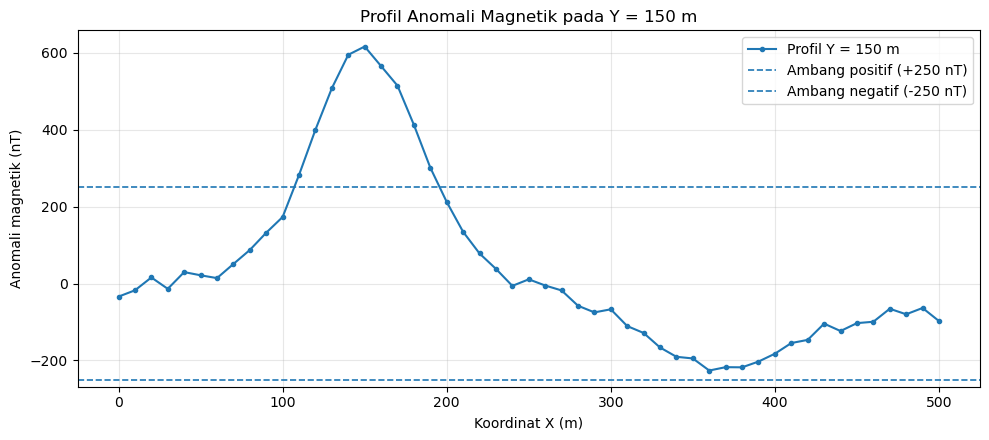



KESIMPULAN INTERPRETASI

Anomali positif kuat ditemukan di sekitar X = 151.2 m dan Y = 128.1 m.
Anomali positif dapat berkaitan dengan batuan atau mineral yang memiliki sifat kemagnetan relatif tinggi.

Anomali negatif kuat ditemukan di sekitar X = 363.8 m dan Y = 189.6 m.
Anomali negatif dapat berkaitan dengan kontras magnetisasi, arah magnetisasi, atau kondisi geologi setempat.

REKOMENDASI
1. Lakukan pemetaan geologi untuk mengetahui jenis batuan dan struktur.
2. Korelasikan anomali dengan singkapan dan data geokimia.
3. Gunakan metode resistivitas atau IP untuk menguji karakteristik bawah permukaan yang berbeda.
4. Pertimbangkan survei lanjutan sebelum menetapkan target pengeboran.

CATATAN:
Data yang digunakan adalah data sintetis untuk latihan. Anomali magnetik tidak secara langsung membuktikan keberadaan mineralisasi besi atau endapan ekonomis.

Program selesai dijalankan.


In [27]:
# ============================================================
# TUGAS AI GEOFISIKA
# PROMPT 2: PEMETAAN ZONA MINERALISASI MENGGUNAKAN METODE MAGNETIK
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Mengatur angka acak agar hasil simulasi konsisten
np.random.seed(42)

print("=" * 65)
print("PEMETAAN ZONA MINERALISASI MENGGUNAKAN METODE MAGNETIK")
print("=" * 65)


# ------------------------------------------------------------
# 1. MEMBUAT GRID KOORDINAT SURVEI
# ------------------------------------------------------------

# Koordinat survei dalam meter
x = np.arange(0, 501, 10)
y = np.arange(0, 301, 10)

# Membuat grid dua dimensi
X, Y = np.meshgrid(x, y)

print("\nGrid survei berhasil dibuat.")
print(f"Panjang lintasan X : {x.min()} - {x.max()} meter")
print(f"Lebar area Y       : {y.min()} - {y.max()} meter")


# ------------------------------------------------------------
# 2. MEMBUAT MODEL ANOMALI MAGNETIK SINTETIS
# ------------------------------------------------------------

# Anomali latar belakang akibat variasi magnetik regional
background = (
    60 * np.sin(X / 95)
    + 35 * np.cos(Y / 65)
)

# Anomali positif yang kuat, misalnya dari sumber batuan bermagnet
anomaly_positive = 800 * np.exp(
    -(
        ((X - 150) / 45) ** 2
        + ((Y - 130) / 35) ** 2
    )
)

# Anomali negatif, yang dapat berkaitan dengan kontras magnetisasi
anomaly_negative = -350 * np.exp(
    -(
        ((X - 360) / 60) ** 2
        + ((Y - 190) / 45) ** 2
    )
)

# Menggabungkan seluruh komponen anomali
magnetic = (
    background
    + anomaly_positive
    + anomaly_negative
)

# Menambahkan noise untuk meniru variasi data pengukuran
noise = np.random.normal(0, 15, magnetic.shape)
magnetic = magnetic + noise

print("\nModel anomali magnetik berhasil dibuat.")
print(f"Anomali minimum : {magnetic.min():.2f} nT")
print(f"Anomali maksimum: {magnetic.max():.2f} nT")


# ------------------------------------------------------------
# 3. MENDETEKSI ZONA ANOMALI MAGNETIK
# ------------------------------------------------------------

# Ambang anomali kuat untuk simulasi ini
threshold = 250

# Memisahkan anomali positif dan negatif
positive_mask = magnetic >= threshold
negative_mask = magnetic <= -threshold

# Menghitung jumlah sel anomali
jumlah_positif = int(positive_mask.sum())
jumlah_negatif = int(negative_mask.sum())

print("\nHASIL DETEKSI ANOMALI")
print("-" * 45)
print(f"Ambang anomali kuat : ±{threshold} nT")
print(f"Jumlah sel anomali positif: {jumlah_positif}")
print(f"Jumlah sel anomali negatif: {jumlah_negatif}")


# ------------------------------------------------------------
# 4. MEMBUAT TABEL RINGKASAN ZONA ANOMALI
# ------------------------------------------------------------

hasil_zona = []

# Menganalisis anomali positif
if np.any(positive_mask):
    hasil_zona.append({
        "Zona": "Anomali positif",
        "X rata-rata (m)": round(X[positive_mask].mean(), 1),
        "Y rata-rata (m)": round(Y[positive_mask].mean(), 1),
        "Anomali rata-rata (nT)": round(
            magnetic[positive_mask].mean(), 2
        ),
        "Anomali minimum (nT)": round(
            magnetic[positive_mask].min(), 2
        ),
        "Anomali maksimum (nT)": round(
            magnetic[positive_mask].max(), 2
        ),
        "Jumlah sel": jumlah_positif
    })

# Menganalisis anomali negatif
if np.any(negative_mask):
    hasil_zona.append({
        "Zona": "Anomali negatif",
        "X rata-rata (m)": round(X[negative_mask].mean(), 1),
        "Y rata-rata (m)": round(Y[negative_mask].mean(), 1),
        "Anomali rata-rata (nT)": round(
            magnetic[negative_mask].mean(), 2
        ),
        "Anomali minimum (nT)": round(
            magnetic[negative_mask].min(), 2
        ),
        "Anomali maksimum (nT)": round(
            magnetic[negative_mask].max(), 2
        ),
        "Jumlah sel": jumlah_negatif
    })

if hasil_zona:
    tabel_hasil = pd.DataFrame(hasil_zona)

    print("\nTABEL HASIL ANALISIS ZONA")
    display(tabel_hasil)
else:
    print("\nTidak ditemukan anomali yang melewati ambang.")


# ------------------------------------------------------------
# 5. VISUALISASI PETA ANOMALI MAGNETIK
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 6))

# Menampilkan distribusi anomali magnetik
peta = ax.pcolormesh(
    X,
    Y,
    magnetic,
    cmap="RdBu_r",
    shading="auto"
)

# Menambahkan garis kontur ambang anomali
ax.contour(
    X,
    Y,
    magnetic,
    levels=[-threshold, threshold],
    colors="black",
    linewidths=1.5
)

# Menandai lokasi pusat rata-rata anomali positif
if np.any(positive_mask):
    x_pos = X[positive_mask].mean()
    y_pos = Y[positive_mask].mean()

    ax.scatter(
        x_pos,
        y_pos,
        color="yellow",
        edgecolors="black",
        marker="o",
        s=100,
        label="Pusat anomali positif"
    )

# Menandai lokasi pusat rata-rata anomali negatif
if np.any(negative_mask):
    x_neg = X[negative_mask].mean()
    y_neg = Y[negative_mask].mean()

    ax.scatter(
        x_neg,
        y_neg,
        color="cyan",
        edgecolors="black",
        marker="s",
        s=80,
        label="Pusat anomali negatif"
    )

# Pengaturan grafik
ax.set_title(
    "Peta Anomali Magnetik untuk Eksplorasi Mineral",
    fontsize=14
)
ax.set_xlabel("Koordinat X (m)")
ax.set_ylabel("Koordinat Y (m)")
ax.set_aspect("equal")

fig.colorbar(
    peta,
    ax=ax,
    label="Anomali magnetik (nT)"
)

ax.legend(loc="upper right")
ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6. VISUALISASI PROFIL ANOMALI MAGNETIK
# ------------------------------------------------------------

# Mengambil profil terdekat dengan Y = 150 meter
indeks_y = np.argmin(np.abs(y - 150))

profil_x = x
profil_magnetik = magnetic[indeks_y, :]

plt.figure(figsize=(10, 4.5))

plt.plot(
    profil_x,
    profil_magnetik,
    marker="o",
    markersize=3,
    linewidth=1.5,
    label=f"Profil Y = {y[indeks_y]} m"
)

plt.axhline(
    threshold,
    linestyle="--",
    linewidth=1.2,
    label=f"Ambang positif (+{threshold} nT)"
)

plt.axhline(
    -threshold,
    linestyle="--",
    linewidth=1.2,
    label=f"Ambang negatif (-{threshold} nT)"
)

plt.title("Profil Anomali Magnetik pada Y = 150 m")
plt.xlabel("Koordinat X (m)")
plt.ylabel("Anomali magnetik (nT)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 7. INTERPRETASI DAN KESIMPULAN OTOMATIS
# ------------------------------------------------------------

print("\n")
print("=" * 65)
print("KESIMPULAN INTERPRETASI")
print("=" * 65)

if np.any(positive_mask):
    print(
        f"\nAnomali positif kuat ditemukan di sekitar "
        f"X = {X[positive_mask].mean():.1f} m dan "
        f"Y = {Y[positive_mask].mean():.1f} m."
    )

    print(
        "Anomali positif dapat berkaitan dengan batuan atau mineral "
        "yang memiliki sifat kemagnetan relatif tinggi."
    )
else:
    print("\nTidak ditemukan anomali positif yang melewati ambang.")

if np.any(negative_mask):
    print(
        f"\nAnomali negatif kuat ditemukan di sekitar "
        f"X = {X[negative_mask].mean():.1f} m dan "
        f"Y = {Y[negative_mask].mean():.1f} m."
    )

    print(
        "Anomali negatif dapat berkaitan dengan kontras magnetisasi, "
        "arah magnetisasi, atau kondisi geologi setempat."
    )
else:
    print("\nTidak ditemukan anomali negatif yang melewati ambang.")

print("\nREKOMENDASI")
print(
    "1. Lakukan pemetaan geologi untuk mengetahui jenis batuan dan struktur."
)
print(
    "2. Korelasikan anomali dengan singkapan dan data geokimia."
)
print(
    "3. Gunakan metode resistivitas atau IP untuk menguji karakteristik "
    "bawah permukaan yang berbeda."
)
print(
    "4. Pertimbangkan survei lanjutan sebelum menetapkan target pengeboran."
)

print("\nCATATAN:")
print(
    "Data yang digunakan adalah data sintetis untuk latihan. "
    "Anomali magnetik tidak secara langsung membuktikan keberadaan "
    "mineralisasi besi atau endapan ekonomis."
)

print("\nProgram selesai dijalankan.")

---

##### **Prompt 3: Identifikasi Zona Mineralisasi Menggunakan Metode Elektromagnetik**

- **R — Role (Peran)**

    Kamu adalah seorang ahli geofisika eksplorasi yang memiliki keahlian dalam metode elektromagnetik (EM) untuk mendeteksi mineral konduktif di bawah permukaan.

- **T — Task (Tugas)**
    
    Interpretasikan data elektromagnetik untuk mengidentifikasi zona konduktivitas tinggi yang berpotensi berkaitan dengan mineralisasi sulfida atau mineral logam konduktif.

- **C — Context (Konteks)**

    Survei elektromagnetik dilakukan pada daerah prospek mineral yang diduga memiliki endapan sulfida. Metode EM memanfaatkan respons medan elektromagnetik sekunder yang dihasilkan oleh arus induksi dalam material konduktif di bawah permukaan.

- **I — Input (Masukan)**
    
    Data yang tersedia berupa:
    
    -  Nilai konduktivitas semu antara 5–500 mS/m.
    
    -  Data respons in-phase dan quadrature.
    
    -  Informasi jarak antarstasiun pengukuran sebesar 10 meter.
    
    -  Informasi geologi awal berupa batuan vulkanik dan zona alterasi.

- **K — Constraints (Batasan)**

    1. Gunakan prinsip induksi elektromagnetik dan konduktivitas listrik batuan.

    2. Pertimbangkan pengaruh kedalaman, ukuran, dan geometri tubuh konduktif.

    3. Jangan menyimpulkan bahwa semua zona konduktivitas tinggi merupakan endapan mineral.

    4. Perhatikan kemungkinan pengaruh lempung, air tanah, dan mineral konduktif non-ekonomis.

- **O — Output (Hasil)**
    
    Sajikan:
    
    1. Tabel zona konduktivitas tinggi beserta kemungkinan penyebabnya.
    
    2. Interpretasi dugaan kedalaman dan geometri zona konduktif jika data mendukung.
    
    3. Identifikasi target eksplorasi mineral yang perlu diteliti lebih lanjut.
    
    4. Rekomendasi survei lanjutan untuk menguji interpretasi.

- **Q — Quality Criteria (Kriteria Kualitas)**

    Jawaban harus menjelaskan hubungan antara konduktivitas dan mineralisasi, menggunakan satuan yang benar, serta membedakan hasil pengukuran langsung dari hasil interpretasi.

- **V — Verification (Verifikasi)**
    Periksa konsistensi nilai konduktivitas, satuan, dan respons elektromagnetik. Pastikan dugaan zona mineralisasi didukung oleh pola anomali dan informasi geologi, serta jelaskan keterbatasan dalam menentukan jenis mineral dari data EM saja.



##### **Implementasi Phyton dan Output**

IDENTIFIKASI ZONA MINERALISASI MENGGUNAKAN METODE EM

Grid survei berhasil dibuat.
Panjang area X : 0 - 300 meter
Lebar area Y   : 0 - 150 meter

Model konduktivitas berhasil dibuat.
Konduktivitas minimum : 17.94 mS/m
Konduktivitas maksimum: 404.44 mS/m

HASIL DETEKSI ZONA KONDUKTIF
---------------------------------------------
Ambang konduktivitas : 150 mS/m
Jumlah sel anomali   : 109

TABEL HASIL ANALISIS


,Parameter,Hasil
0,Koordinat X minimum (m),135.00
1,Koordinat X maksimum (m),205.00
2,Koordinat Y minimum (m),55.00
3,Koordinat Y maksimum (m),95.00
4,Konduktivitas rata-rata (mS/m),253.92
5,Konduktivitas maksimum (mS/m),404.44
6,Jumlah sel anomali,109.00


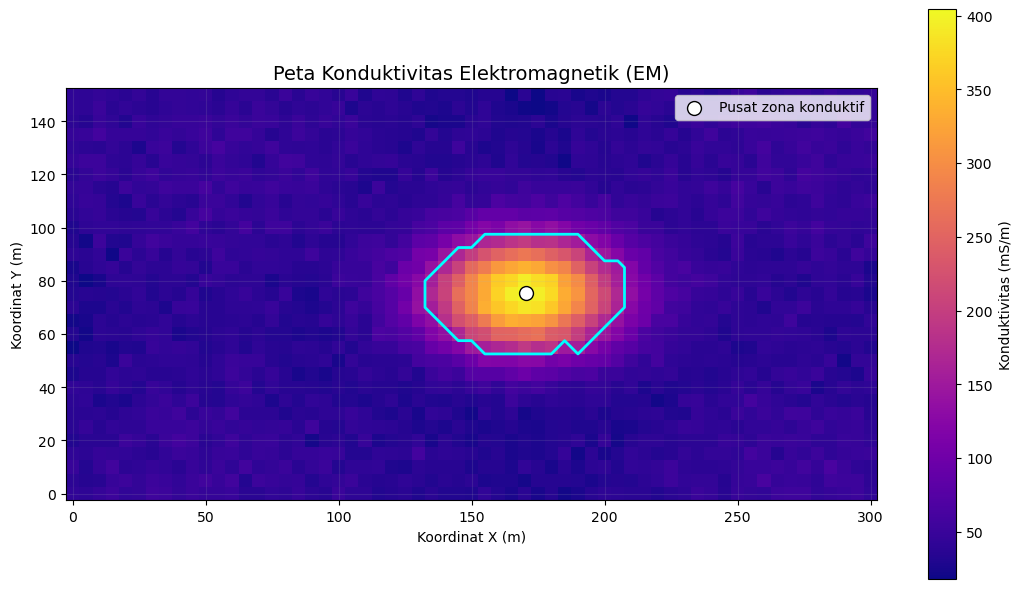

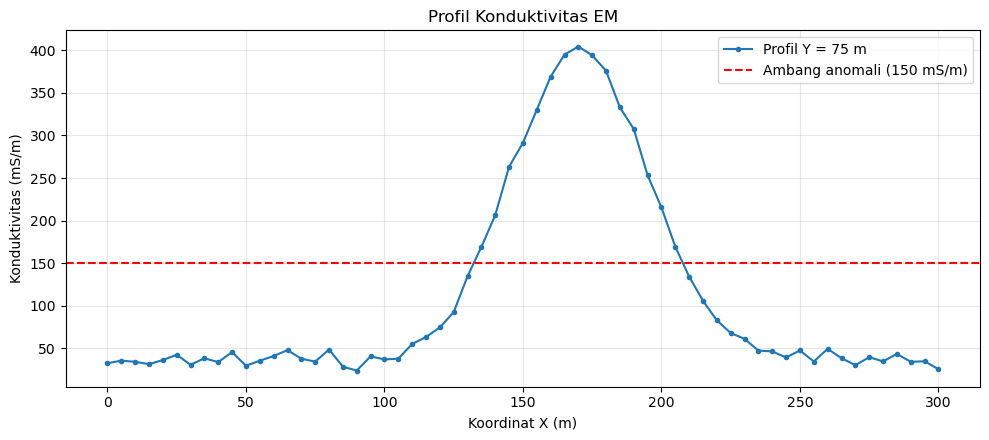



KESIMPULAN INTERPRETASI

Zona konduktif terdeteksi pada koordinat X sekitar 135-205 meter.
Rentang koordinat Y sekitar 55-95 meter.
Konduktivitas rata-rata zona anomali adalah 253.92 mS/m.

Interpretasi awal: konduktivitas tinggi dapat menunjukkan material yang lebih konduktif dibandingkan batuan sekitarnya.
Kemungkinan penyebabnya meliputi mineral sulfida konduktif, mineral lempung, atau fluida yang mengisi pori dan rekahan.

REKOMENDASI
1. Lakukan pemetaan geologi untuk mengetahui litologi dan struktur.
2. Gunakan metode IP atau resistivitas untuk menguji karakter zona konduktif.
3. Korelasikan hasil dengan data geokimia dan singkapan batuan.
4. Evaluasi konfigurasi, frekuensi, dan kedalaman investigasi EM sebelum menentukan target eksplorasi.

CATATAN
Data yang digunakan merupakan data sintetis untuk latihan. Peta ini bukan hasil inversi EM dan tidak dapat menentukan kedalaman atau jenis mineral secara pasti.

Program selesai dijalankan.


In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Mengatur angka acak agar hasil simulasi konsisten
np.random.seed(42)

print("=" * 65)
print("IDENTIFIKASI ZONA MINERALISASI MENGGUNAKAN METODE EM")
print("=" * 65)


# ------------------------------------------------------------
# 1. MEMBUAT GRID KOORDINAT SURVEI
# ------------------------------------------------------------

# Koordinat area survei dalam meter
x = np.arange(0, 301, 5)
y = np.arange(0, 151, 5)

# Membuat grid dua dimensi
X, Y = np.meshgrid(x, y)

print("\nGrid survei berhasil dibuat.")
print(f"Panjang area X : {x.min()} - {x.max()} meter")
print(f"Lebar area Y   : {y.min()} - {y.max()} meter")


# ------------------------------------------------------------
# 2. MEMBUAT MODEL KONDUKTIVITAS SINTETIS
# ------------------------------------------------------------

# Konduktivitas latar belakang (mS/m)
background = (
    35
    + 8 * np.sin(X / 35)
    + 5 * np.cos(Y / 20)
)

# Membuat tubuh konduktif sintetis di tengah area
# Pusat anomali sekitar X = 170 m dan Y = 75 m
conductive_body = np.exp(
    -(
        ((X - 170) / 35) ** 2
        + ((Y - 75) / 22) ** 2
    )
)

# Menggabungkan latar belakang dan anomali konduktif
conductivity = background + 380 * conductive_body

# Menambahkan noise untuk meniru variasi pengukuran
noise = np.random.normal(0, 6, conductivity.shape)
conductivity = conductivity + noise

# Memastikan nilai konduktivitas positif
conductivity = np.clip(conductivity, 1, None)

print("\nModel konduktivitas berhasil dibuat.")
print(f"Konduktivitas minimum : {conductivity.min():.2f} mS/m")
print(f"Konduktivitas maksimum: {conductivity.max():.2f} mS/m")


# ------------------------------------------------------------
# 3. MENDETEKSI ZONA KONDUKTIF
# ------------------------------------------------------------

# Ambang konduktivitas tinggi untuk simulasi ini
threshold = 150

# Menandai sel yang memiliki konduktivitas di atas ambang
anomali = conductivity >= threshold

jumlah_anomali = int(anomali.sum())

print("\nHASIL DETEKSI ZONA KONDUKTIF")
print("-" * 45)
print(f"Ambang konduktivitas : {threshold} mS/m")
print(f"Jumlah sel anomali   : {jumlah_anomali}")


# ------------------------------------------------------------
# 4. ANALISIS DAN TABEL ZONA ANOMALI
# ------------------------------------------------------------

if np.any(anomali):

    # Menentukan batas zona anomali
    x_min = X[anomali].min()
    x_max = X[anomali].max()
    y_min = Y[anomali].min()
    y_max = Y[anomali].max()

    # Menghitung nilai rata-rata konduktivitas pada zona anomali
    conductivity_mean = conductivity[anomali].mean()

    # Membuat tabel ringkasan
    hasil = pd.DataFrame({
        "Parameter": [
            "Koordinat X minimum (m)",
            "Koordinat X maksimum (m)",
            "Koordinat Y minimum (m)",
            "Koordinat Y maksimum (m)",
            "Konduktivitas rata-rata (mS/m)",
            "Konduktivitas maksimum (mS/m)",
            "Jumlah sel anomali"
        ],
        "Hasil": [
            x_min,
            x_max,
            y_min,
            y_max,
            round(conductivity_mean, 2),
            round(conductivity[anomali].max(), 2),
            jumlah_anomali
        ]
    })

    print("\nTABEL HASIL ANALISIS")
    display(hasil)

else:
    print("Tidak ditemukan zona konduktif yang memenuhi ambang.")


# ------------------------------------------------------------
# 5. VISUALISASI PETA KONDUKTIVITAS EM
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 6))

# Membuat peta konduktivitas
peta = ax.pcolormesh(
    X,
    Y,
    conductivity,
    cmap="plasma",
    shading="auto"
)

# Menampilkan batas zona konduktif
if np.any(anomali):
    ax.contour(
        X,
        Y,
        anomali.astype(float),
        levels=[0.5],
        colors="cyan",
        linewidths=2
    )

    # Menandai pusat rata-rata zona anomali
    x_center = X[anomali].mean()
    y_center = Y[anomali].mean()

    ax.scatter(
        x_center,
        y_center,
        color="white",
        edgecolors="black",
        marker="o",
        s=100,
        label="Pusat zona konduktif"
    )

# Pengaturan grafik
ax.set_title(
    "Peta Konduktivitas Elektromagnetik (EM)",
    fontsize=14
)
ax.set_xlabel("Koordinat X (m)")
ax.set_ylabel("Koordinat Y (m)")
ax.set_aspect("equal")

fig.colorbar(
    peta,
    ax=ax,
    label="Konduktivitas (mS/m)"
)

ax.legend(loc="upper right")
ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6. VISUALISASI PROFIL KONDUKTIVITAS
# ------------------------------------------------------------

# Mengambil profil terdekat dengan Y = 75 meter
indeks_y = np.argmin(np.abs(y - 75))

profil_x = x
profil_konduktivitas = conductivity[indeks_y, :]

plt.figure(figsize=(10, 4.5))

plt.plot(
    profil_x,
    profil_konduktivitas,
    marker="o",
    markersize=3,
    linewidth=1.5,
    label=f"Profil Y = {y[indeks_y]} m"
)

# Menampilkan ambang konduktivitas
plt.axhline(
    threshold,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=f"Ambang anomali ({threshold} mS/m)"
)

plt.title("Profil Konduktivitas EM")
plt.xlabel("Koordinat X (m)")
plt.ylabel("Konduktivitas (mS/m)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 7. INTERPRETASI DAN KESIMPULAN OTOMATIS
# ------------------------------------------------------------

print("\n")
print("=" * 65)
print("KESIMPULAN INTERPRETASI")
print("=" * 65)

if np.any(anomali):

    print(
        f"\nZona konduktif terdeteksi pada koordinat X sekitar "
        f"{x_min:.0f}-{x_max:.0f} meter."
    )

    print(
        f"Rentang koordinat Y sekitar "
        f"{y_min:.0f}-{y_max:.0f} meter."
    )

    print(
        f"Konduktivitas rata-rata zona anomali adalah "
        f"{conductivity_mean:.2f} mS/m."
    )

    print(
        "\nInterpretasi awal: konduktivitas tinggi dapat menunjukkan "
        "material yang lebih konduktif dibandingkan batuan sekitarnya."
    )

    print(
        "Kemungkinan penyebabnya meliputi mineral sulfida konduktif, "
        "mineral lempung, atau fluida yang mengisi pori dan rekahan."
    )

else:
    print(
        "\nTidak ditemukan zona konduktif yang melewati ambang "
        "pada model ini."
    )

print("\nREKOMENDASI")
print(
    "1. Lakukan pemetaan geologi untuk mengetahui litologi dan struktur."
)
print(
    "2. Gunakan metode IP atau resistivitas untuk menguji karakter "
    "zona konduktif."
)
print(
    "3. Korelasikan hasil dengan data geokimia dan singkapan batuan."
)
print(
    "4. Evaluasi konfigurasi, frekuensi, dan kedalaman investigasi EM "
    "sebelum menentukan target eksplorasi."
)

print("\nCATATAN")
print(
    "Data yang digunakan merupakan data sintetis untuk latihan. "
    "Peta ini bukan hasil inversi EM dan tidak dapat menentukan "
    "kedalaman atau jenis mineral secara pasti."
)

print("\nProgram selesai dijalankan.")

---
##### **Prompt 4: Karakterisasi Zona Mineralisasi Menggunakan Metode Magnetotellurik**

- **R — Role (Peran)**
    
    Kamu adalah seorang ahli geofisika yang berpengalaman dalam metode Magnetotellurik (MT) untuk pemetaan struktur resistivitas bawah permukaan dalam eksplorasi mineral.

- **T — Task (Tugas)**
    
    Analisis model resistivitas hasil inversi MT untuk mengidentifikasi struktur geologi, zona alterasi, dan kemungkinan jalur fluida hidrotermal yang berhubungan dengan mineralisasi logam.

- **C — Context (Konteks)**
    
    Survei MT dilakukan pada daerah prospek mineralisasi hidrotermal. Metode MT memanfaatkan variasi alami medan listrik dan medan magnet untuk memperkirakan distribusi resistivitas batuan pada kedalaman yang relatif besar.

- **I — Input (Masukan)**
    
    Data yang tersedia berupa:
    
    - Model resistivitas hasil inversi MT dengan rentang 1–10.000 Ωm.

    - Penampang resistivitas 2D hingga kedalaman 2 km.

    - Data koordinat stasiun MT.

    - Informasi geologi regional berupa sesar, intrusi batuan, dan zona alterasi hidrotermal.

- **K — Constraints (Batasan)**

    1. Gunakan konsep resistivitas dan prinsip dasar metode MT.

    2. Pertimbangkan pengaruh fluida, temperatur, alterasi, dan jenis batuan terhadap resistivitas.

    3. Jangan mengidentifikasi jenis mineral secara pasti hanya dari anomali resistivitas.

    4. Perhatikan keterbatasan resolusi dan ketidakunikan model inversi.

- **O — Output (Hasil)**
    
    Buatlah:
    
    1. Tabel zona resistivitas rendah dan tinggi beserta kemungkinan penyebab geologinya.

    2. Interpretasi hubungan zona konduktif dengan struktur sesar dan alterasi.

    3. Identifikasi zona yang berpotensi menjadi target eksplorasi mineral.

    4. Kesimpulan dan rekomendasi metode pendukung.

- **Q — Quality Criteria (Kriteria Kualitas)**
    
    Interpretasi harus sesuai dengan prinsip MT, menggunakan satuan yang benar, serta menghubungkan hasil model resistivitas dengan kondisi geologi secara logis dan ilmiah.

- **V — Verification (Verifikasi)**

    Periksa rentang resistivitas, kedalaman, dan kesesuaian interpretasi dengan informasi geologi. Jelaskan kemungkinan penyebab lain dari anomali konduktif dan jangan menganggap model inversi sebagai gambaran pasti kondisi bawah permukaan.



##### **Implementasi Phyton dan Output**

KARAKTERISASI ZONA MINERALISASI MENGGUNAKAN METODE MT

Grid model berhasil dibuat.
Panjang lintasan : 0 - 400 meter
Kedalaman model  : 0 - 2000 meter

Model resistivitas sintetis berhasil dibuat.
Resistivitas minimum : 1.00 Ohm.m
Resistivitas maksimum: 2547.90 Ohm.m

HASIL DETEKSI ZONA KONDUKTIF
--------------------------------------------------
Ambang resistivitas rendah: 50 Ohm.m
Jumlah sel anomali       : 105

TABEL HASIL ANALISIS MT


,Parameter,Hasil
0,Jarak minimum (m),150.00
1,Jarak maksimum (m),210.00
2,Kedalaman minimum (m),200.00
3,Kedalaman maksimum (m),900.00
4,Resistivitas rata-rata (Ohm.m),15.91
5,Resistivitas minimum (Ohm.m),1.00
6,Resistivitas maksimum (Ohm.m),46.90
7,Jumlah sel anomali,105.00


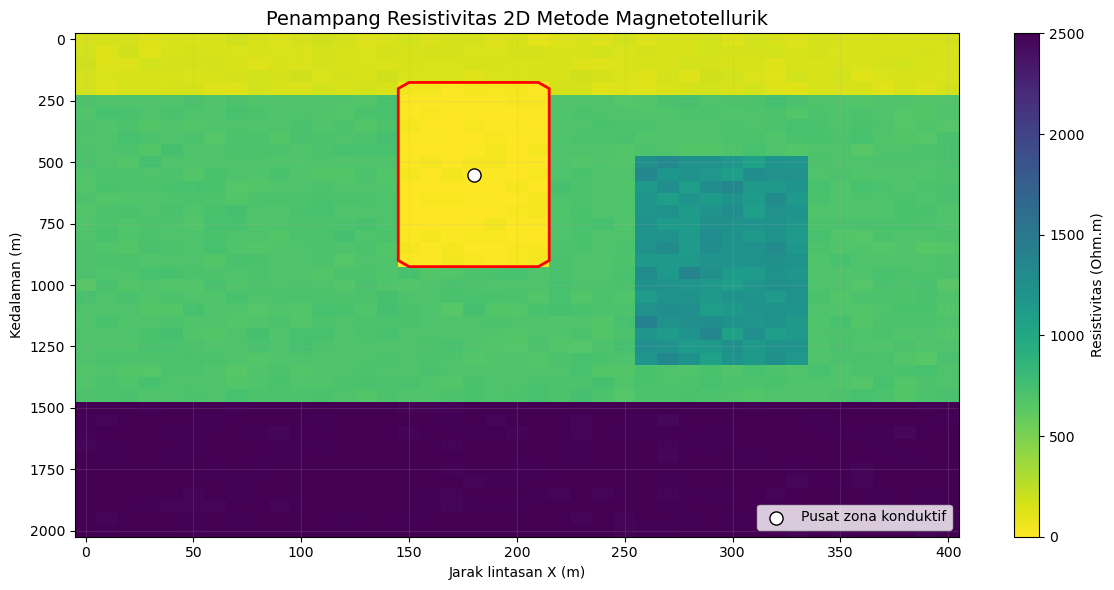

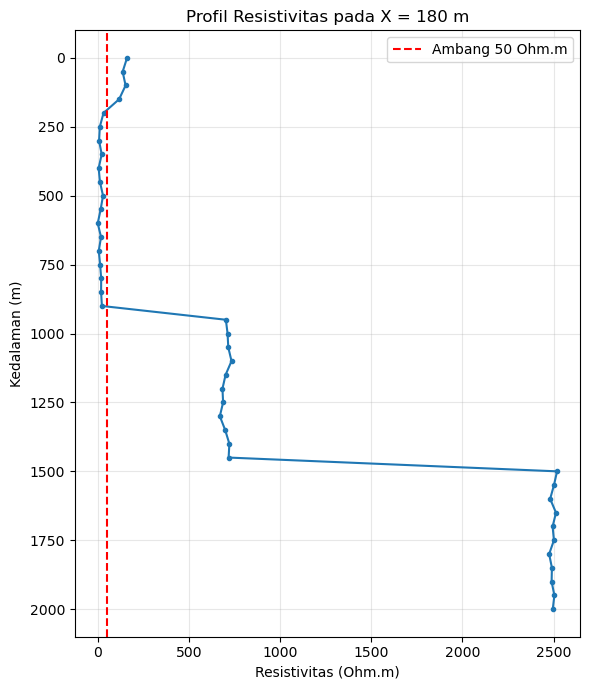



KESIMPULAN INTERPRETASI

Zona resistivitas rendah ditemukan pada X = 150-210 meter.
Kedalaman zona sekitar 200-900 meter.
Resistivitas rata-rata zona adalah 15.91 Ohm.m.

Interpretasi awal: zona resistivitas rendah dapat berkaitan dengan alterasi hidrotermal, fluida pada rekahan, atau material lempung.
Jika berasosiasi dengan struktur sesar dan bukti geologi lainnya, zona tersebut dapat menjadi target penyelidikan lanjutan untuk eksplorasi mineral.

REKOMENDASI
1. Korelasikan model resistivitas dengan peta geologi dan struktur sesar.
2. Gunakan metode IP untuk mengevaluasi kemungkinan mineral sulfida.
3. Lakukan survei geokimia untuk mencari bukti pendukung mineralisasi.
4. Evaluasi kualitas data dan hasil inversi sebelum menentukan target.

CATATAN
Model ini menggunakan data sintetis dan bukan hasil inversi MT lapangan. Batas anomali yang terlihat merupakan bagian dari model yang dibuat, bukan bukti langsung keberadaan mineralisasi.

Program selesai dijalankan.


In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Mengatur angka acak agar hasil simulasi konsisten
np.random.seed(42)

print("=" * 70)
print("KARAKTERISASI ZONA MINERALISASI MENGGUNAKAN METODE MT")
print("=" * 70)


# ------------------------------------------------------------
# 1. MEMBUAT GRID KOORDINAT DAN KEDALAMAN
# ------------------------------------------------------------

# Jarak lintasan horizontal (meter)
x = np.arange(0, 401, 10)

# Kedalaman investigasi (meter)
z = np.arange(0, 2001, 50)

# Membuat grid dua dimensi
X, Z = np.meshgrid(x, z)

print("\nGrid model berhasil dibuat.")
print(f"Panjang lintasan : {x.min()} - {x.max()} meter")
print(f"Kedalaman model  : {z.min()} - {z.max()} meter")


# ------------------------------------------------------------
# 2. MEMBUAT MODEL RESISTIVITAS BAWAH PERMUKAAN
# ------------------------------------------------------------

# Model awal: batuan dengan resistivitas 700 Ohm.m
rho = np.full(X.shape, 700.0)

# Lapisan dangkal yang lebih konduktif
lapisan_dangkal = Z < 250
rho[lapisan_dangkal] = 150.0

# Zona konduktif yang diasosiasikan dengan sesar atau alterasi
zona_konduktif = (
    (X >= 150) & (X <= 210) &
    (Z >= 200) & (Z <= 900)
)

rho[zona_konduktif] = (
    15 + np.random.normal(
        0, 2, np.count_nonzero(zona_konduktif)
    )
)

# Zona resistif yang diasosiasikan dengan batuan intrusi
zona_intrusi = (
    (X >= 260) & (X <= 330) &
    (Z >= 500) & (Z <= 1300)
)

rho[zona_intrusi] = (
    1200 + np.random.normal(
        0, 60, np.count_nonzero(zona_intrusi)
    )
)

# Batuan dasar yang lebih resistif
batuan_dasar = Z >= 1500
rho[batuan_dasar] = 2500.0

# Menambahkan variasi kecil pada model
rho += np.random.normal(0, 15, rho.shape)

# Memastikan nilai resistivitas tetap positif
rho = np.clip(rho, 1, None)

print("\nModel resistivitas sintetis berhasil dibuat.")
print(f"Resistivitas minimum : {rho.min():.2f} Ohm.m")
print(f"Resistivitas maksimum: {rho.max():.2f} Ohm.m")


# ------------------------------------------------------------
# 3. MENDETEKSI ZONA RESISTIVITAS RENDAH
# ------------------------------------------------------------

# Ambang resistivitas rendah untuk simulasi
threshold = 50

# Membuat mask untuk zona resistivitas rendah
anomali = rho < threshold

jumlah_anomali = int(anomali.sum())

print("\nHASIL DETEKSI ZONA KONDUKTIF")
print("-" * 50)
print(f"Ambang resistivitas rendah: {threshold} Ohm.m")
print(f"Jumlah sel anomali       : {jumlah_anomali}")


# ------------------------------------------------------------
# 4. ANALISIS DAN TABEL ZONA ANOMALI
# ------------------------------------------------------------

if np.any(anomali):

    # Batas horizontal dan kedalaman zona anomali
    x_min = X[anomali].min()
    x_max = X[anomali].max()
    z_min = Z[anomali].min()
    z_max = Z[anomali].max()

    # Statistik resistivitas zona anomali
    rho_mean = rho[anomali].mean()
    rho_min = rho[anomali].min()
    rho_max = rho[anomali].max()

    # Membuat tabel hasil
    hasil = pd.DataFrame({
        "Parameter": [
            "Jarak minimum (m)",
            "Jarak maksimum (m)",
            "Kedalaman minimum (m)",
            "Kedalaman maksimum (m)",
            "Resistivitas rata-rata (Ohm.m)",
            "Resistivitas minimum (Ohm.m)",
            "Resistivitas maksimum (Ohm.m)",
            "Jumlah sel anomali"
        ],
        "Hasil": [
            x_min,
            x_max,
            z_min,
            z_max,
            round(rho_mean, 2),
            round(rho_min, 2),
            round(rho_max, 2),
            jumlah_anomali
        ]
    })

    print("\nTABEL HASIL ANALISIS MT")
    display(hasil)

else:
    print("Tidak ditemukan zona resistivitas rendah.")


# ------------------------------------------------------------
# 5. VISUALISASI PENAMPANG RESISTIVITAS 2D
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 6))

# Menampilkan distribusi resistivitas bawah permukaan
peta = ax.pcolormesh(
    X,
    Z,
    rho,
    cmap="viridis_r",
    shading="auto",
    vmin=0,
    vmax=2500
)

# Menampilkan kontur batas zona resistivitas rendah
if np.any(anomali):
    ax.contour(
        X,
        Z,
        anomali.astype(float),
        levels=[0.5],
        colors="red",
        linewidths=2
    )

    # Menandai pusat zona resistivitas rendah
    x_center = X[anomali].mean()
    z_center = Z[anomali].mean()

    ax.scatter(
        x_center,
        z_center,
        color="white",
        edgecolors="black",
        s=90,
        marker="o",
        label="Pusat zona konduktif"
    )

ax.set_title(
    "Penampang Resistivitas 2D Metode Magnetotellurik",
    fontsize=14
)

ax.set_xlabel("Jarak lintasan X (m)")
ax.set_ylabel("Kedalaman (m)")
ax.invert_yaxis()

fig.colorbar(
    peta,
    ax=ax,
    label="Resistivitas (Ohm.m)"
)

ax.legend(loc="lower right")
ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6. VISUALISASI PROFIL RESISTIVITAS TERHADAP KEDALAMAN
# ------------------------------------------------------------

# Memilih lintasan pada X = 180 meter
indeks_x = np.argmin(np.abs(x - 180))

profil_kedalaman = z
profil_resistivitas = rho[:, indeks_x]

plt.figure(figsize=(6, 7))

plt.plot(
    profil_resistivitas,
    profil_kedalaman,
    marker="o",
    markersize=3,
    linewidth=1.5
)

# Menandai ambang resistivitas rendah
plt.axvline(
    threshold,
    color="red",
    linestyle="--",
    label=f"Ambang {threshold} Ohm.m"
)

plt.title("Profil Resistivitas pada X = 180 m")
plt.xlabel("Resistivitas (Ohm.m)")
plt.ylabel("Kedalaman (m)")
plt.gca().invert_yaxis()
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 7. INTERPRETASI DAN KESIMPULAN OTOMATIS
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("KESIMPULAN INTERPRETASI")
print("=" * 70)

if np.any(anomali):

    print(
        f"\nZona resistivitas rendah ditemukan pada X = "
        f"{x_min:.0f}-{x_max:.0f} meter."
    )

    print(
        f"Kedalaman zona sekitar {z_min:.0f}-{z_max:.0f} meter."
    )

    print(
        f"Resistivitas rata-rata zona adalah "
        f"{rho_mean:.2f} Ohm.m."
    )

    print(
        "\nInterpretasi awal: zona resistivitas rendah dapat "
        "berkaitan dengan alterasi hidrotermal, fluida pada rekahan, "
        "atau material lempung."
    )

    print(
        "Jika berasosiasi dengan struktur sesar dan bukti geologi "
        "lainnya, zona tersebut dapat menjadi target penyelidikan "
        "lanjutan untuk eksplorasi mineral."
    )

else:
    print(
        "\nTidak ditemukan zona resistivitas rendah berdasarkan "
        "ambang yang ditentukan."
    )

print("\nREKOMENDASI")
print(
    "1. Korelasikan model resistivitas dengan peta geologi dan struktur sesar."
)
print(
    "2. Gunakan metode IP untuk mengevaluasi kemungkinan mineral sulfida."
)
print(
    "3. Lakukan survei geokimia untuk mencari bukti pendukung mineralisasi."
)
print(
    "4. Evaluasi kualitas data dan hasil inversi sebelum menentukan target."
)

print("\nCATATAN")
print(
    "Model ini menggunakan data sintetis dan bukan hasil inversi MT lapangan. "
    "Batas anomali yang terlihat merupakan bagian dari model yang dibuat, "
    "bukan bukti langsung keberadaan mineralisasi."
)

print("\nProgram selesai dijalankan.")

---
##### **Prompt 5: Integrasi Metode Geofisika untuk Penentuan Target Eksplorasi Mineral**

- **R — Role (Peran)**

    Kamu adalah seorang ahli geofisika eksplorasi yang berpengalaman dalam integrasi data geolistrik, IP, magnetik, dan elektromagnetik untuk eksplorasi mineral logam.

- **T — Task (Tugas)**

    Integrasikan data dari beberapa metode geofisika untuk menentukan zona target eksplorasi mineral yang memiliki dukungan anomali paling konsisten berdasarkan karakteristik geofisika dan kondisi geologi.

- **C — Context (Konteks)**
    
    Suatu daerah prospek mineral telah disurvei menggunakan beberapa metode geofisika. Setiap metode memberikan informasi yang berbeda, seperti resistivitas, chargeability, sifat kemagnetan, dan konduktivitas batuan. Integrasi dilakukan untuk mengurangi ketidakpastian interpretasi dan memperoleh gambaran bawah permukaan yang lebih menyeluruh.

- **I — Input (Masukan)**
    
    Data yang tersedia meliputi:
    
    - Data resistivitas dengan rentang 20–2.000 Ωm.
    
    - Data chargeability dengan rentang 1–60 mV/V.

    - Peta anomali magnetik dengan rentang -500 hingga 1.000 nT.

    - Data konduktivitas elektromagnetik dengan rentang 5–500 mS/m.

    - Informasi geologi berupa litologi, struktur sesar, dan zona alterasi.

- **K — Constraints (Batasan)**

    1. Gunakan prinsip dasar masing-masing metode geofisika.

    2. Pertimbangkan perbedaan resolusi, kedalaman investigasi, dan sensitivitas setiap metode.

    3. Jangan menyimpulkan keberadaan mineral hanya berdasarkan satu anomali.

    4. Jangan memberikan kepastian mengenai kadar atau jumlah cadangan mineral tanpa data geologi dan pengeboran.

    5. Jika terdapat perbedaan hasil antar metode, jelaskan kemungkinan penyebabnya.

- **O — Output (Hasil)**
    
    Sajikan hasil dalam bentuk:
    
    1. Tabel perbandingan hasil setiap metode geofisika.
    
    2. Peta atau tabel zona target berdasarkan koordinat jika data tersedia.
    
    3. Penjelasan hubungan antara anomali geofisika dan kondisi geologi.
    
    4. Rekomendasi lokasi survei lanjutan atau pengeboran eksplorasi beserta alasannya.
    
    5. Kesimpulan mengenai tingkat dukungan data terhadap setiap zona target tanpa menyatakan kepastian keberadaan bijih.

- **Q — Quality Criteria (Kriteria Kualitas)**

    Hasil integrasi harus konsisten secara ilmiah, mempertimbangkan kelebihan dan keterbatasan setiap metode, serta menjelaskan alasan pemilihan zona target berdasarkan bukti yang tersedia.

- **V — Verification (Verifikasi)**

    Periksa kesesuaian koordinat, satuan, rentang nilai, dan kedalaman investigasi setiap metode. Pastikan seluruh data mengacu pada sistem koordinat yang konsisten. Identifikasi kemungkinan interpretasi alternatif dan nyatakan bagian yang masih membutuhkan validasi lapangan atau pengeboran.



##### **Implementasi Phyton dan Output**

INTEGRASI METODE GEOFISIKA UNTUK TARGET EKSPLORASI MINERAL

Area survei:
Koordinat X : 0 - 300 meter
Koordinat Y : 0 - 150 meter

Deteksi anomali selesai.
Skor maksimum: 5 dari 5 indikator.

TABEL 10 BLOK TARGET TERATAS


,Peringkat,X blok (m),Y blok (m),Skor rata-rata,Dukungan metode (%),Resistivitas (Ohm.m),IP (mV/V),Magnetik (nT),EM (mS/m),MT (Ohm.m),Kategori
0,1,225,25,3.28,65.6,73.79,22.55,205.16,137.40,148.57,Prioritas tinggi
1,2,100,75,2.96,59.2,54.78,29.28,75.13,175.97,128.70,Prioritas menengah
2,3,125,75,2.64,52.8,66.24,25.64,56.33,156.97,128.57,Prioritas menengah
3,4,225,50,2.24,44.8,90.87,18.90,153.84,114.68,167.43,Prioritas menengah
4,5,100,50,2.20,44.0,73.85,24.70,78.37,147.65,150.84,Prioritas menengah
5,6,125,50,1.76,35.2,83.83,20.10,55.56,130.83,146.54,Prioritas rendah
6,7,200,25,1.48,29.6,109.91,15.74,131.82,96.97,164.29,Prioritas rendah
7,8,200,50,0.84,16.8,117.11,13.42,93.59,80.91,178.35,Prioritas rendah
8,9,75,75,0.32,6.4,152.40,11.23,43.16,82.67,216.67,Prioritas rendah
9,10,250,25,0.28,5.6,163.54,12.04,87.21,67.42,216.37,Prioritas rendah


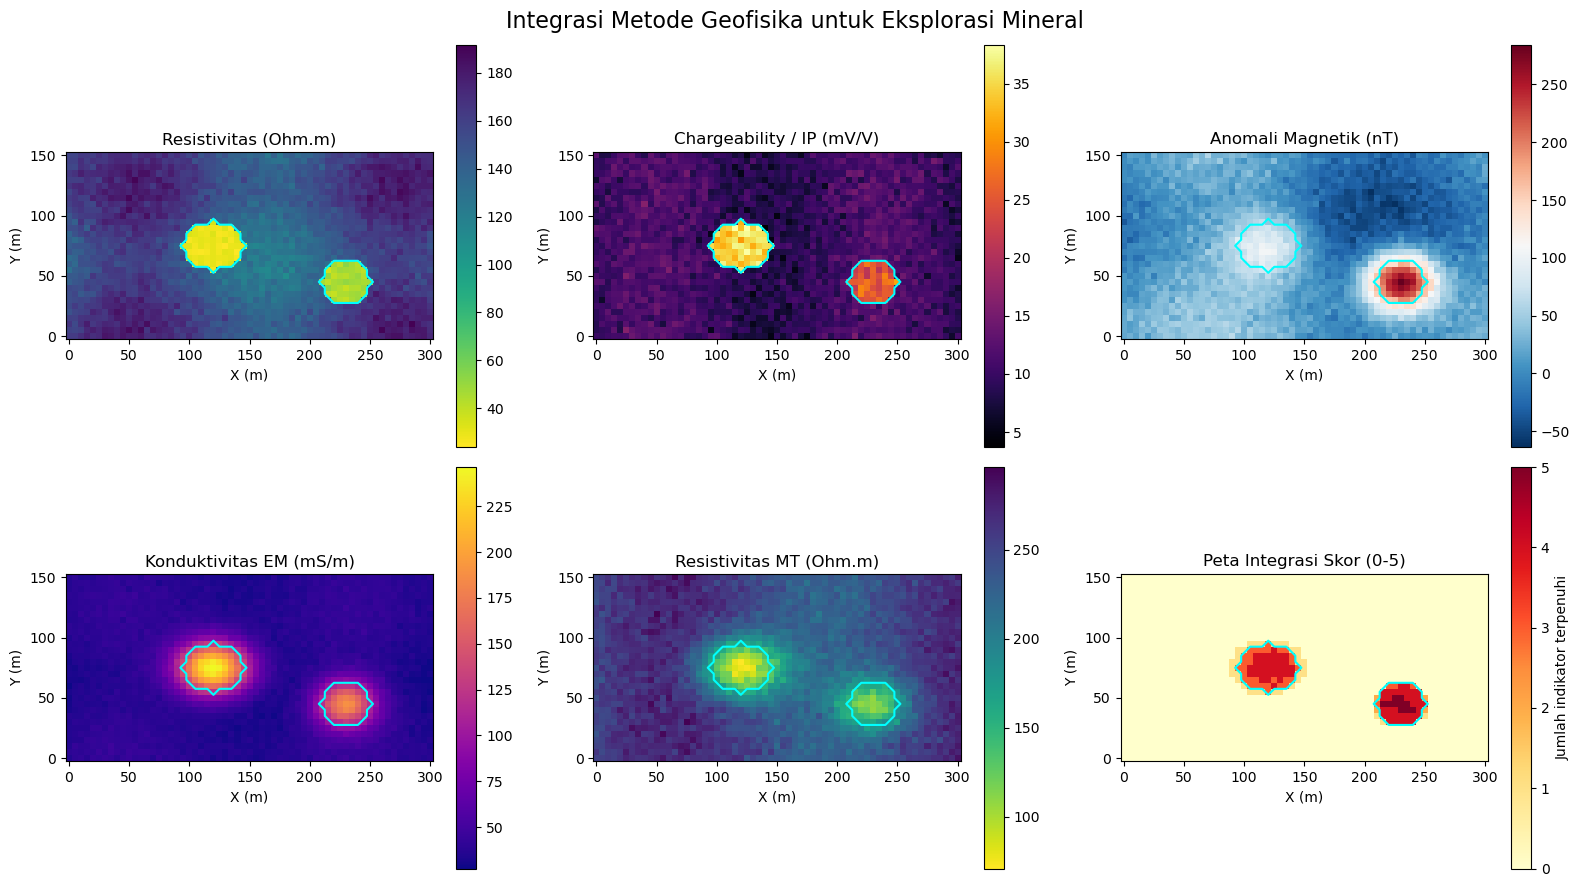

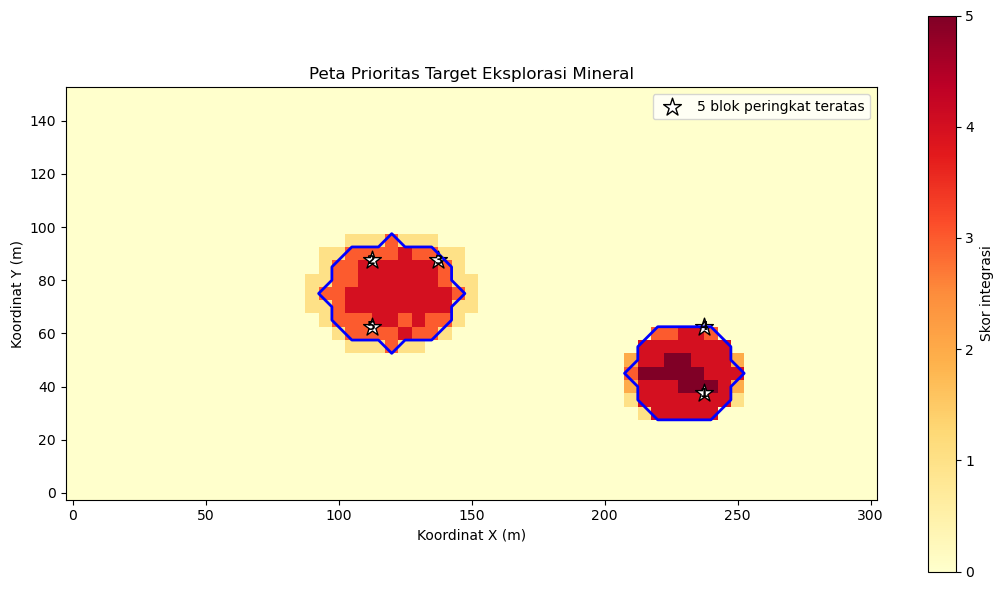



KESIMPULAN INTEGRASI GEOFISIKA

Jumlah sel dengan dukungan minimal 3 dari 5 indikator: 110

Lima blok dengan skor tertinggi:
Peringkat 1: X=225-250 m, Y=25-50 m, skor=3.28/5, kategori=Prioritas tinggi
Peringkat 2: X=100-125 m, Y=75-100 m, skor=2.96/5, kategori=Prioritas menengah
Peringkat 3: X=125-150 m, Y=75-100 m, skor=2.64/5, kategori=Prioritas menengah
Peringkat 4: X=225-250 m, Y=50-75 m, skor=2.24/5, kategori=Prioritas menengah
Peringkat 5: X=100-125 m, Y=50-75 m, skor=2.20/5, kategori=Prioritas menengah

INTERPRETASI
Blok dengan skor tinggi menunjukkan lokasi yang memenuhi lebih banyak kriteria anomali dalam model sintetis.
Kombinasi resistivitas rendah, chargeability tinggi, konduktivitas tinggi, dan respons magnetik dapat membantu menyusun prioritas penyelidikan, tetapi setiap metode memiliki respons fisik yang berbeda.

REKOMENDASI
1. Periksa kembali data mentah dan kualitas setiap survei.
2. Samakan sistem koordinat, resolusi grid, dan cakupan area.
3. Evaluasi bobot serta 

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)

print("=" * 75)
print("INTEGRASI METODE GEOFISIKA UNTUK TARGET EKSPLORASI MINERAL")
print("=" * 75)


# ------------------------------------------------------------
# 1. MEMBUAT GRID AREA EKSPLORASI
# ------------------------------------------------------------

x = np.arange(0, 301, 5)
y = np.arange(0, 151, 5)

X, Y = np.meshgrid(x, y)

print("\nArea survei:")
print(f"Koordinat X : {x.min()} - {x.max()} meter")
print(f"Koordinat Y : {y.min()} - {y.max()} meter")


# ------------------------------------------------------------
# 2. SIMULASI DATA RESISTIVITAS DAN CHARGEABILITY (IP)
# ------------------------------------------------------------

# Nilai latar belakang resistivitas
rho = (
    150
    + 20 * np.sin(X / 35)
    + 10 * np.cos(Y / 20)
    + np.random.normal(0, 5, X.shape)
)

# Nilai latar belakang chargeability
ip = (
    10
    + 2 * np.sin(X / 30)
    + np.random.normal(0, 1.5, X.shape)
)

# Zona target utama sintetis
target_utama = (
    ((X - 120) / 25) ** 2
    + ((Y - 75) / 20) ** 2
) <= 1

# Zona target kedua sintetis
target_kedua = (
    ((X - 230) / 20) ** 2
    + ((Y - 45) / 18) ** 2
) <= 1

# Respons resistivitas rendah dan IP tinggi pada target utama
rho[target_utama] = (
    30 + np.random.normal(0, 3, target_utama.sum())
)

ip[target_utama] = (
    35 + np.random.normal(0, 2, target_utama.sum())
)

# Respons lebih lemah pada target kedua
rho[target_kedua] = (
    45 + np.random.normal(0, 4, target_kedua.sum())
)

ip[target_kedua] = (
    25 + np.random.normal(0, 2, target_kedua.sum())
)


# ------------------------------------------------------------
# 3. SIMULASI DATA MAGNETIK
# ------------------------------------------------------------

magnetic = (
    30 * np.sin(X / 45)
    + 20 * np.cos(Y / 30)
    + np.random.normal(0, 8, X.shape)
)

# Anomali magnetik positif di sekitar target kedua
magnetic += 300 * np.exp(
    -(
        ((X - 230) / 30) ** 2
        + ((Y - 45) / 25) ** 2
    )
)

# Anomali magnetik lebih lemah di sekitar target utama
magnetic += 100 * np.exp(
    -(
        ((X - 120) / 35) ** 2
        + ((Y - 75) / 30) ** 2
    )
)


# ------------------------------------------------------------
# 4. SIMULASI DATA ELEKTROMAGNETIK (EM)
# ------------------------------------------------------------

conductivity = (
    35
    + 5 * np.sin(X / 30)
    + 3 * np.cos(Y / 20)
    + np.random.normal(0, 2, X.shape)
)

# Konduktivitas tinggi di sekitar target utama
conductivity += 220 * np.exp(
    -(
        ((X - 120) / 30) ** 2
        + ((Y - 75) / 22) ** 2
    )
)

# Konduktivitas tinggi di sekitar target kedua
conductivity += 150 * np.exp(
    -(
        ((X - 230) / 25) ** 2
        + ((Y - 45) / 20) ** 2
    )
)


# ------------------------------------------------------------
# 5. SIMULASI DATA MAGNETOTELLURIK (MT)
# ------------------------------------------------------------

# MT pada simulasi ini diwakili oleh resistivitas semu
# untuk menggambarkan respons konduktivitas regional.
rho_mt = (
    250
    + 25 * np.sin(X / 40)
    + np.random.normal(0, 8, X.shape)
)

# Zona resistivitas rendah di sekitar target utama
rho_mt -= 180 * np.exp(
    -(
        ((X - 120) / 35) ** 2
        + ((Y - 75) / 25) ** 2
    )
)

# Zona resistivitas rendah di sekitar target kedua
rho_mt -= 130 * np.exp(
    -(
        ((X - 230) / 30) ** 2
        + ((Y - 45) / 22) ** 2
    )
)

rho_mt = np.clip(rho_mt, 5, None)


# ------------------------------------------------------------
# 6. MENENTUKAN ANOMALI DARI SETIAP METODE
# ------------------------------------------------------------

# Kriteria contoh untuk data sintetis
anomali_rho = rho < 60
anomali_ip = ip > 20
anomali_magnetik = magnetic > 150
anomali_em = conductivity > 100
anomali_mt = rho_mt < 120

# Menghitung jumlah metode yang mendukung setiap lokasi
skor = (
    anomali_rho.astype(int)
    + anomali_ip.astype(int)
    + anomali_magnetik.astype(int)
    + anomali_em.astype(int)
    + anomali_mt.astype(int)
)

# Persentase dukungan metode
persentase = skor / 5 * 100

# Target prioritas: minimal 3 dari 5 indikator memenuhi kriteria
target_prioritas = skor >= 3

print("\nDeteksi anomali selesai.")
print("Skor maksimum:", skor.max(), "dari 5 indikator.")


# ------------------------------------------------------------
# 7. MEMBUAT TABEL ANALISIS TARGET
# ------------------------------------------------------------

# Membagi area menjadi beberapa blok 25 m x 25 m.
# Skor blok dihitung sebagai rata-rata skor sel di dalamnya.

ukuran_blok = 25
hasil_target = []

for x0 in range(0, 301, ukuran_blok):
    for y0 in range(0, 151, ukuran_blok):

        blok = (
            (X >= x0) & (X < x0 + ukuran_blok)
            & (Y >= y0) & (Y < y0 + ukuran_blok)
        )

        if not np.any(blok):
            continue

        skor_blok = skor[blok].mean()
        rho_blok = rho[blok].mean()
        ip_blok = ip[blok].mean()
        mag_blok = magnetic[blok].mean()
        em_blok = conductivity[blok].mean()
        mt_blok = rho_mt[blok].mean()

        # Klasifikasi berdasarkan rata-rata skor blok
        if skor_blok >= 3:
            kategori = "Prioritas tinggi"
        elif skor_blok >= 2:
            kategori = "Prioritas menengah"
        else:
            kategori = "Prioritas rendah"

        hasil_target.append({
            "X blok (m)": x0,
            "Y blok (m)": y0,
            "Skor rata-rata": round(skor_blok, 2),
            "Dukungan metode (%)": round(skor_blok / 5 * 100, 1),
            "Resistivitas (Ohm.m)": round(rho_blok, 2),
            "IP (mV/V)": round(ip_blok, 2),
            "Magnetik (nT)": round(mag_blok, 2),
            "EM (mS/m)": round(em_blok, 2),
            "MT (Ohm.m)": round(mt_blok, 2),
            "Kategori": kategori
        })

tabel_target = pd.DataFrame(hasil_target)

# Mengurutkan blok berdasarkan skor rata-rata tertinggi
tabel_target = tabel_target.sort_values(
    by="Skor rata-rata",
    ascending=False
).reset_index(drop=True)

# Memberikan nomor peringkat
tabel_target.insert(
    0,
    "Peringkat",
    np.arange(1, len(tabel_target) + 1)
)

print("\nTABEL 10 BLOK TARGET TERATAS")
display(tabel_target.head(10))


# ------------------------------------------------------------
# 8. VISUALISASI LIMA INDIKATOR GEOFISIKA
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

# Peta resistivitas
p1 = axes[0, 0].pcolormesh(
    X, Y, rho,
    cmap="viridis_r",
    shading="auto"
)
axes[0, 0].set_title("Resistivitas (Ohm.m)")
axes[0, 0].set_xlabel("X (m)")
axes[0, 0].set_ylabel("Y (m)")
fig.colorbar(p1, ax=axes[0, 0])

# Peta chargeability
p2 = axes[0, 1].pcolormesh(
    X, Y, ip,
    cmap="inferno",
    shading="auto"
)
axes[0, 1].set_title("Chargeability / IP (mV/V)")
axes[0, 1].set_xlabel("X (m)")
axes[0, 1].set_ylabel("Y (m)")
fig.colorbar(p2, ax=axes[0, 1])

# Peta magnetik
p3 = axes[0, 2].pcolormesh(
    X, Y, magnetic,
    cmap="RdBu_r",
    shading="auto"
)
axes[0, 2].set_title("Anomali Magnetik (nT)")
axes[0, 2].set_xlabel("X (m)")
axes[0, 2].set_ylabel("Y (m)")
fig.colorbar(p3, ax=axes[0, 2])

# Peta konduktivitas EM
p4 = axes[1, 0].pcolormesh(
    X, Y, conductivity,
    cmap="plasma",
    shading="auto"
)
axes[1, 0].set_title("Konduktivitas EM (mS/m)")
axes[1, 0].set_xlabel("X (m)")
axes[1, 0].set_ylabel("Y (m)")
fig.colorbar(p4, ax=axes[1, 0])

# Peta resistivitas MT
p5 = axes[1, 1].pcolormesh(
    X, Y, rho_mt,
    cmap="viridis_r",
    shading="auto"
)
axes[1, 1].set_title("Resistivitas MT (Ohm.m)")
axes[1, 1].set_xlabel("X (m)")
axes[1, 1].set_ylabel("Y (m)")
fig.colorbar(p5, ax=axes[1, 1])

# Peta integrasi skor
p6 = axes[1, 2].pcolormesh(
    X, Y, skor,
    cmap="YlOrRd",
    shading="auto",
    vmin=0,
    vmax=5
)

axes[1, 2].set_title("Peta Integrasi Skor (0-5)")
axes[1, 2].set_xlabel("X (m)")
axes[1, 2].set_ylabel("Y (m)")
fig.colorbar(
    p6,
    ax=axes[1, 2],
    ticks=[0, 1, 2, 3, 4, 5],
    label="Jumlah indikator terpenuhi"
)

# Menampilkan batas target prioritas pada semua peta
for ax in axes.flat:
    ax.contour(
        X, Y, target_prioritas.astype(float),
        levels=[0.5],
        colors="cyan",
        linewidths=1.5
    )

    ax.set_aspect("equal")

fig.suptitle(
    "Integrasi Metode Geofisika untuk Eksplorasi Mineral",
    fontsize=16
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 9. PETA PERINGKAT TARGET EKSPLORASI
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 6))

peta_skor = ax.pcolormesh(
    X,
    Y,
    skor,
    cmap="YlOrRd",
    shading="auto",
    vmin=0,
    vmax=5
)

# Kontur target dengan dukungan minimal tiga indikator
ax.contour(
    X,
    Y,
    target_prioritas.astype(float),
    levels=[0.5],
    colors="blue",
    linewidths=2
)

# Menampilkan pusat setiap blok dengan skor tertinggi
top = tabel_target.head(5)

ax.scatter(
    top["X blok (m)"] + ukuran_blok / 2,
    top["Y blok (m)"] + ukuran_blok / 2,
    marker="*",
    s=180,
    color="white",
    edgecolors="black",
    label="5 blok peringkat teratas"
)

for _, baris in top.iterrows():
    ax.annotate(
        f'{int(baris["Peringkat"])}',
        (
            baris["X blok (m)"] + ukuran_blok / 2,
            baris["Y blok (m)"] + ukuran_blok / 2
        ),
        ha="center",
        va="center",
        fontsize=9,
        fontweight="bold"
    )

ax.set_title("Peta Prioritas Target Eksplorasi Mineral")
ax.set_xlabel("Koordinat X (m)")
ax.set_ylabel("Koordinat Y (m)")
ax.set_aspect("equal")

fig.colorbar(
    peta_skor,
    ax=ax,
    ticks=[0, 1, 2, 3, 4, 5],
    label="Skor integrasi"
)

ax.legend(loc="upper right")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. KESIMPULAN OTOMATIS
# ------------------------------------------------------------

print("\n")
print("=" * 75)
print("KESIMPULAN INTEGRASI GEOFISIKA")
print("=" * 75)

jumlah_prioritas = int(target_prioritas.sum())

print(
    f"\nJumlah sel dengan dukungan minimal 3 dari 5 indikator: "
    f"{jumlah_prioritas}"
)

print("\nLima blok dengan skor tertinggi:")

for _, baris in tabel_target.head(5).iterrows():
    print(
        f"Peringkat {int(baris['Peringkat'])}: "
        f"X={int(baris['X blok (m)'])}-{int(baris['X blok (m)']) + ukuran_blok} m, "
        f"Y={int(baris['Y blok (m)'])}-{int(baris['Y blok (m)']) + ukuran_blok} m, "
        f"skor={baris['Skor rata-rata']:.2f}/5, "
        f"kategori={baris['Kategori']}"
    )

print("\nINTERPRETASI")
print(
    "Blok dengan skor tinggi menunjukkan lokasi yang memenuhi lebih "
    "banyak kriteria anomali dalam model sintetis."
)

print(
    "Kombinasi resistivitas rendah, chargeability tinggi, konduktivitas "
    "tinggi, dan respons magnetik dapat membantu menyusun prioritas "
    "penyelidikan, tetapi setiap metode memiliki respons fisik yang berbeda."
)

print("\nREKOMENDASI")
print(
    "1. Periksa kembali data mentah dan kualitas setiap survei."
)
print(
    "2. Samakan sistem koordinat, resolusi grid, dan cakupan area."
)
print(
    "3. Evaluasi bobot serta ambang anomali berdasarkan kondisi geologi."
)
print(
    "4. Validasi target dengan pemetaan geologi, geokimia, dan data lapangan."
)
print(
    "5. Tentukan pengeboran hanya setelah evaluasi terpadu dan kelayakan target."
)

print("\nCATATAN PENTING")
print(
    "Semua data dalam program ini merupakan simulasi sintetis. "
    "Skor menunjukkan kesesuaian terhadap kriteria yang dibuat, bukan "
    "probabilitas ditemukannya mineral atau kadar bijih."
)

print("\nProgram selesai dijalankan.")

## **<center>Sekian dan Terimakasih</center>**